# 06 – Modell B: erweitertes Logit

Modell B = Modell A (mit `grdummy`, nicht A2) **plus neun weitere Kennzahlen** aus `firm_year_ratios.csv`. Modell A bleibt unverändert.

Ablauf: neue Variablen aufbereiten (Abschnitt 1), auf starke Korrelationen prüfen (Abschnitt 2), die Entscheidung zur Variablenliste umsetzen (Abschnitt 3), dann Modell B schätzen und mit Modell A vergleichen (Abschnitte 4–7).

## Die neuen Variablen

Quelle = was im Pipeline-Code (`src/15_compute_ratios.py`), im Datenwörterbuch (`docs/data_dictionary.md`) bzw. im archivierten Modellcode dokumentiert ist. Wo dort **keine** Quelle steht, ist das so vermerkt.

| Variable | Formel | Quelle laut Code/Doku |
|---|---|---|
| `fcf_to_assets` | (operativer Cashflow − Capex) / Bilanzsumme | **keine Quelle im Code**; inhaltlich Free-Cashflow-These (Jensen; Lehn & Poulsen 1989; Opler & Titman 1993 – siehe PROGRESS.md) |
| `fcf_vol` | Standardabweichung von `fcf_to_assets` über t, t−1, t−2 (sonst 2 Jahre) | Jiang (2019), `FCFFvol` |
| `interest_coverage` | operatives Ergebnis / Zinsaufwand (nur bei Zinsaufwand > 0) | **keine Quelle im Code**; Jiang (2019) führt eine ähnliche Variable `EBITCov` (laut PROGRESS.md, dort n.s.) |
| `ppe_to_assets` | Sachanlagen / Bilanzsumme | Jiang (2019), `PPEpct` |
| `rd_to_assets` | F&E-Aufwand / Bilanzsumme | Variante von Jiang (2019) `RDpct` (dort F&E/Umsatz); auf die Bilanzsumme bezogen, damit auch Firmen ohne Umsatz einen Wert haben |
| `cash_ratio` | Cash / Bilanzsumme | **keine Quelle im Code** (im archivierten Kernset „cash“ ohne Zitat) |
| `altman_z2` | Altman Z'' für Nicht-Industriefirmen: 6,56·X1 + 3,26·X2 + 6,72·X3 + 1,05·X4 (X4 mit Float statt Marktwert) | Altman (Z''-Score); für Finanzfirmen nicht definiert |
| `roa` | Nettoergebnis / Bilanzsumme | **keine Quelle im Code** (im archivierten Kernset „profitability“ ohne Zitat) |
| `log_float` | ln(Streubesitzwert, EntityPublicFloat) | Größe über den Marktwert, Jiang (2019) `lnMktCap` (archivierter Code); Float statt Marktkapitalisierung (design_memo.md, Abschnitt 6) |

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("..") / "data" / "processed"
Y = "y_pe_main_h3"

# Ausgangspunkt: Modell-A-Datensatz aus Notebook 04 (Palepu-Variablen schon aufbereitet)
data = pd.read_csv(DATA / "model_data_palepu.csv", dtype={"cik": str})
palepu_vars = ["roe", "sales_growth_1y", "liquidity", "leverage", "grdummy", "idummy",
               "log_assets", "float_to_book", "float_to_earnings"]
palepu_ind = sorted(c for c in data.columns if c.endswith("_missing"))

# Neue Kennzahlen als ROHWERTE dazuholen (über accession)
new_vars = ["fcf_to_assets", "fcf_vol", "interest_coverage", "ppe_to_assets", "rd_to_assets",
            "cash_ratio", "altman_z2", "roa", "log_float"]
ratios = pd.read_csv(DATA / "firm_year_ratios.csv", usecols=["accession"] + new_vars)
data = data.merge(ratios, on="accession", how="left", validate="one_to_one")
train = data["split"] == "train"
print(f"{len(data):,} Zeilen, davon Training {train.sum():,} mit {int(data.loc[train, Y].sum())} Positiven")

33,428 Zeilen, davon Training 18,058 mit 167 Positiven


## 1. Aufbereitung der neuen Variablen (Regeln wie in Notebook 04)

Winsorisieren auf das 1./99. Perzentil, Median-Imputation, Fehlend-Indikator nur bei >2 % fehlend **und** ≥ 5 Positiven in der Lücke – alles nur aus dem Training berechnet. Die Palepu-Variablen sind schon aufbereitet und werden nicht angefasst.

In [2]:
lo = data.loc[train, new_vars].quantile(0.01)
hi = data.loc[train, new_vars].quantile(0.99)
median = data.loc[train, new_vars].clip(lo, hi, axis=1).median()

rows = []
for v in new_vars:
    missing = data[v].isna()
    share = missing[train].mean()
    pos_in_gap = int(data.loc[train & missing, Y].sum())
    keep_ind = share > 0.02 and pos_in_gap >= 5
    clipped = (data[v] < lo[v]) | (data[v] > hi[v])
    rows.append({"Variable": v, "P1 (Train)": lo[v], "P99 (Train)": hi[v], "Median (Train)": median[v],
                 "fehlt Train": f"{share:.1%}", "fehlt Test": f"{missing[data['split'] == 'test'].mean():.1%}",
                 "gekappt Train": int(clipped[train].sum()), "gekappt Test": int(clipped[data["split"] == "test"].sum()),
                 "Positive in Lücke": pos_in_gap, "Indikator": "ja" if keep_ind else "nein"})
    if keep_ind:
        data[f"{v}_missing"] = missing.astype(int)
    data[v] = data[v].clip(lo[v], hi[v]).fillna(median[v])

new_ind = [f"{v}_missing" for v in new_vars if f"{v}_missing" in data.columns]
assert data[new_vars].notna().all().all()
pd.DataFrame(rows).set_index("Variable").round(4)

,P1 (Train),P99 (Train),Median (Train),fehlt Train,fehlt Test,gekappt Train,gekappt Test,Positive in Lücke,Indikator
Variable,,,,,,,,,
fcf_to_assets,-5.1250,0.3051,0.0357,11.8%,11.7%,320,134,24,ja
fcf_vol,0.0010,1.1252,0.0292,33.9%,22.2%,240,128,54,ja
interest_coverage,-2796.9730,2191.1641,3.1393,31.7%,33.9%,248,171,26,ja
ppe_to_assets,0.0000,0.9441,0.1415,0.9%,0.5%,179,52,3,nein
rd_to_assets,0.0000,0.8605,0.0000,0.9%,0.5%,187,66,3,nein
cash_ratio,0.0002,0.9815,0.0879,2.0%,0.9%,356,114,5,nein
altman_z2,-59.3757,184.0696,4.1048,22.3%,16.6%,282,266,37,ja
roa,-14.1255,0.3061,0.0250,1.8%,1.2%,356,179,6,nein
log_float,17.7778,25.6214,20.5801,5.0%,3.5%,344,323,4,nein


In [3]:
B_VARS = palepu_vars + new_vars
B_IND = palepu_ind + new_ind
print(f"Modell B hätte {len(B_VARS)} Variablen und {len(B_IND)} Fehlend-Indikatoren:")
print("  neue Indikatoren:", new_ind)

Modell B hätte 18 Variablen und 10 Fehlend-Indikatoren:
  neue Indikatoren: ['fcf_to_assets_missing', 'fcf_vol_missing', 'interest_coverage_missing', 'altman_z2_missing']


**Ergebnis:** Vier der neun neuen Variablen bekommen einen Fehlend-Indikator: `fcf_to_assets`, `fcf_vol`, `interest_coverage`, `altman_z2`. `fcf_vol` fehlt am häufigsten (34 % im Training), weil es drei aufeinanderfolgende Jahre braucht. `interest_coverage` fehlt bei 32 %, weil es nur für Firmen mit Zinsaufwand definiert ist. Wie bei den Palepu-Variablen sind einige Grenzen sehr weit (`interest_coverage` ±2.000–2.800, `roa` bis −14, `fcf_to_assets` bis −5) – das sind wieder vor allem Firmen mit fast leerer Bilanz.

## 2. Korrelationen (Training, nach Aufbereitung)

Stark korrelierte Variablen messen fast dasselbe. In einem Logit führt das zu instabilen Koeffizienten: Das Modell kann den gemeinsamen Effekt kaum auf die beiden Variablen aufteilen, die Standardfehler werden groß, und Vorzeichen können kippen. Geprüft werden alle Paare (Variablen und Indikatoren) mit |r| > 0,7, auf den Trainingsdaten so, wie sie ins Modell gingen.

In [4]:
cols = B_VARS + B_IND
corr = data.loc[train, cols].corr()

pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) > 0.7:
            pairs.append({"Variable 1": a, "Variable 2": b, "r": round(r, 3)})
high = pd.DataFrame(pairs).sort_values("r", key=abs, ascending=False) if pairs else pd.DataFrame()
print(f"Paare mit |r| > 0.7: {len(high)}")
high

Paare mit |r| > 0.7: 6


,Variable 1,Variable 2,r
3,grdummy_missing,sales_growth_1y_missing,0.847
2,float_to_book_missing,float_to_earnings_missing,0.787
1,fcf_to_assets,roa,0.775
4,grdummy_missing,fcf_vol_missing,0.714
5,sales_growth_1y_missing,fcf_vol_missing,0.702
0,liquidity,roa,0.701


In [5]:
# Zum Vergleich die vermuteten Paare, auch wenn sie unter 0,7 liegen
for a, b in [("log_assets", "log_float"), ("roa", "roe"), ("cash_ratio", "liquidity"),
             ("roa", "fcf_to_assets"), ("altman_z2", "roa"), ("altman_z2", "liquidity"), ("leverage", "interest_coverage")]:
    print(f"{a:>14s} / {b:<18s} r = {corr.loc[a, b]:+.3f}")

    log_assets / log_float          r = +0.626
           roa / roe                r = +0.173
    cash_ratio / liquidity          r = +0.000
           roa / fcf_to_assets      r = +0.775
     altman_z2 / roa                r = +0.055
     altman_z2 / liquidity          r = +0.079
      leverage / interest_coverage  r = -0.013


### Gegenprobe: Rangkorrelation (Spearman)

Pearson misst lineare Zusammenhänge und reagiert stark auf Extremwerte. Spearman korreliert nur die **Ränge** (wer ist größer als wer) und ist deshalb robust gegen Ausreißer. Weichen beide stark voneinander ab, wird der Pearson-Wert von wenigen extremen Zeilen bestimmt.

In [6]:
spear = data.loc[train, cols].corr(method="spearman")
pairs_s = [{"Variable 1": a, "Variable 2": b, "Spearman": round(spear.loc[a, b], 3), "Pearson": round(corr.loc[a, b], 3)}
           for i, a in enumerate(cols) for b in cols[i + 1:] if abs(spear.loc[a, b]) > 0.7 or abs(corr.loc[a, b]) > 0.7]
display(pd.DataFrame(pairs_s).sort_values("Spearman", key=abs, ascending=False).set_index(["Variable 1", "Variable 2"]))

# Woher kommen die Pearson-Werte bei liquidity? Firmen mit fast leerer Bilanz haben extreme Werte in ALLEN
# Kennzahlen, die durch die Bilanzsumme geteilt werden (gemeinsamer Nenner).
extreme = train & (data["liquidity"] < -1)
print(f"Trainingszeilen mit liquidity < -1: {extreme.sum()}")
for a, b in [("roa", "liquidity"), ("cash_ratio", "liquidity"), ("roa", "fcf_to_assets")]:
    r_without = data.loc[train & ~extreme, [a, b]].corr().iloc[0, 1]
    print(f"{a:>13s} / {b:<14s} Pearson alle: {corr.loc[a, b]:+.2f} | ohne diese Zeilen: {r_without:+.2f} | Spearman: {spear.loc[a, b]:+.2f}")

,,Spearman,Pearson
Variable 1,Variable 2,,
roe,roa,0.849,0.173
grdummy_missing,sales_growth_1y_missing,0.847,0.847
float_to_book_missing,float_to_earnings_missing,0.787,0.787
log_assets,log_float,0.783,0.626
grdummy_missing,fcf_vol_missing,0.714,0.714
sales_growth_1y_missing,fcf_vol_missing,0.702,0.702
fcf_to_assets,roa,0.654,0.775
liquidity,roa,-0.073,0.701


Trainingszeilen mit liquidity < -1: 394
          roa / liquidity      Pearson alle: +0.70 | ohne diese Zeilen: -0.05 | Spearman: -0.07
   cash_ratio / liquidity      Pearson alle: +0.00 | ohne diese Zeilen: +0.72 | Spearman: +0.48
          roa / fcf_to_assets  Pearson alle: +0.78 | ohne diese Zeilen: +0.76 | Spearman: +0.65


**Ergebnis:** Nach Pearson gibt es 6 Paare über 0,7, nach Spearman andere – das Bild hängt vom Maß ab:

- **Echt ähnliche Variablen (Spearman hoch):** `roe`/`roa` (Spearman 0,85, Pearson nur 0,17) und `log_assets`/`log_float` (Spearman 0,78, Pearson 0,63). Beide Paare messen inhaltlich fast dasselbe (Rendite bzw. Größe).
- **Scheinbare Korrelation durch Ausreißer:** `roa`/`liquidity` (Pearson 0,70) verschwindet ohne die rund 400 Zeilen mit `liquidity` < −1 fast vollständig (Spearman −0,07). Diese Firmen haben fast keine Bilanzsumme, und weil alle drei Kennzahlen durch die Bilanzsumme geteilt werden, sind sie bei ihnen gleichzeitig extrem. Umgekehrt verdecken die Ausreißer bei `cash_ratio`/`liquidity` einen echten Zusammenhang (Pearson 0,00, ohne sie 0,72).
- **`roa`/`fcf_to_assets`:** in beiden Maßen hoch (Pearson 0,78, Spearman 0,65) – Gewinn und Free Cashflow hängen eng zusammen.
- **Indikator-Paare:** `grdummy_missing`, `sales_growth_1y_missing` und `fcf_vol_missing` (0,70–0,85) messen alle „kein Vorjahresbericht vorhanden“ (z. B. FY2012, Neuemissionen); ebenso `float_to_book_missing`/`float_to_earnings_missing` (0,79), die beide fehlen, wenn der Float 0 ist (IPO-Ausnahme).

### Optionen, die zur Entscheidung vorlagen

Optionen, je mit Vor- und Nachteilen:

1. **Alles behalten.** + vollständig, keine willkürliche Auswahl; Vorhersagegüte (AUC) leidet unter Korrelation kaum. − Koeffizienten der korrelierten Paare sind instabil und schwer zu deuten (große Standardfehler, Vorzeichen können kippen) – schlecht für den Vorzeichen-Vergleich mit Palepu.
2. **Pro Paar eine Variable streichen, Palepu-Variable behalten** (z. B. `roa` und `log_float` raus, `roe` und `log_assets` bleiben). + stabil und gut deutbar; Modell A bleibt vollständig in B enthalten, sodass A und B sauber vergleichbar sind (Likelihood-Ratio-Test). − Information der gestrichenen Variable geht verloren; Auswahl muss begründet werden.
3. **Pro Paar die „bessere“ Variable nach Theorie wählen** (z. B. `log_float` als Marktgröße statt Buchgröße). + inhaltlich stärker. − A ist dann nicht mehr in B enthalten; der A/B-Vergleich wird unsauberer.
4. **Paare zusammenfassen** (z. B. Mittelwert der standardisierten Werte oder Hauptkomponente). + keine Information verloren. − neue, schwer erklärbare Variable – das wäre ein neues Feature.
5. **Indikatoren:** die redundanten Indikatoren zusammenlegen oder einen pro Gruppe behalten (z. B. nur `sales_growth_1y_missing` statt zusätzlich `grdummy_missing` und `fcf_vol_missing`). + weniger instabile Koeffizienten. − weicht von der Indikator-Regel aus 04 ab.

Zusätzlich zu entscheiden: **welches Maß** für die 0,7-Schwelle gilt (Pearson, Spearman oder beide), denn die Ausreißer-Firmen verzerren Pearson stark. Der geplante Robustheitscheck ohne Firmen mit Bilanzsumme < 10 Mio. USD würde genau diese Zeilen entfernen.

## 3. Entscheidung zur Variablenliste (29.10.2026)

- **Maß:** Spearman, Schwelle |rho| > 0,7.
- **Korrelierte Paare:** Die Palepu-Variable bleibt, die neue fällt weg → **`roa` und `log_float` sind nicht in Modell B.** Damit ist Modell A vollständig in Modell B enthalten.
- **Indikatoren:** Die Indikatoren aus Modell A bleiben unverändert; neue Indikatoren mit |rho| > 0,7 zu einem bestehenden fallen weg.
- Dieselbe Liste gilt später für Random Forest und XGBoost (Modell C).

In [7]:
B_NEW = [v for v in new_vars if v not in ("roa", "log_float")]

# Neue Indikatoren nur behalten, wenn sie mit keinem Modell-A-Indikator |rho| > 0.7 haben
B_NEW_IND = []
for ind in new_ind:
    rho_max = spear.loc[ind, palepu_ind].abs().max()
    print(f"{ind:28s} max |rho| zu Modell-A-Indikatoren: {rho_max:.3f} -> {'weg' if rho_max > 0.7 else 'bleibt'}")
    if rho_max <= 0.7:
        B_NEW_IND.append(ind)

A_COLS = palepu_vars + palepu_ind                       # genau wie Modell A in Notebook 05
B_COLS = palepu_vars + B_NEW + palepu_ind + B_NEW_IND
print(f"\nModell A: {len(A_COLS)} Spalten | Modell B: {len(B_COLS)} Spalten")
print("Neu in B:", B_NEW + B_NEW_IND)

# Kontrolle: Welche Paare mit |rho| > 0.7 gibt es in der endgültigen B-Liste noch?
rest = [(a, b, round(spear.loc[a, b], 3)) for i, a in enumerate(B_COLS) for b in B_COLS[i + 1:] if abs(spear.loc[a, b]) > 0.7]
print("Verbleibende Paare |rho| > 0.7:", rest)

fcf_to_assets_missing        max |rho| zu Modell-A-Indikatoren: 0.409 -> bleibt
fcf_vol_missing              max |rho| zu Modell-A-Indikatoren: 0.714 -> weg
interest_coverage_missing    max |rho| zu Modell-A-Indikatoren: 0.180 -> bleibt
altman_z2_missing            max |rho| zu Modell-A-Indikatoren: 0.647 -> bleibt

Modell A: 15 Spalten | Modell B: 25 Spalten
Neu in B: ['fcf_to_assets', 'fcf_vol', 'interest_coverage', 'ppe_to_assets', 'rd_to_assets', 'cash_ratio', 'altman_z2', 'fcf_to_assets_missing', 'interest_coverage_missing', 'altman_z2_missing']
Verbleibende Paare |rho| > 0.7: [('float_to_book_missing', 'float_to_earnings_missing', np.float64(0.787)), ('grdummy_missing', 'sales_growth_1y_missing', np.float64(0.847))]


**Ergebnis:** `fcf_vol_missing` fällt weg (rho 0,71 zu einem Modell-A-Indikator), die drei anderen neuen Indikatoren bleiben. Modell B hat damit 25 Spalten statt 15: sieben neue Kennzahlen und drei neue Indikatoren. Die zwei verbleibenden Paare über 0,7 sind Indikatoren aus Modell A, die nach deiner Entscheidung unverändert bleiben.

## 4. Modell B schätzen (und Modell A zum Vergleich neu schätzen)

Gleiches Setup wie Modell A in Notebook 05: unregularisiert, ungewichtet, Standardfehler nach Firma geclustert, nur Training FY2012–2017. Modell A wird hier mit identischem Code neu geschätzt, damit beide Modelle direkt verglichen werden können (Kontrolle: gleiches Pseudo-R² wie in 05).

In [8]:
import statsmodels.api as sm

tr = data[data["split"] == "train"]
te = data[data["split"] == "test"].copy()

def fit_logit(cols):
    return sm.Logit(tr[Y], sm.add_constant(tr[cols])).fit(
        method="newton", maxiter=100, disp=False, cov_type="cluster", cov_kwds={"groups": tr["cik"]})

res_a, res_b = fit_logit(A_COLS), fit_logit(B_COLS)
print("Konvergiert: A", res_a.mle_retvals["converged"], "| B", res_b.mle_retvals["converged"])
print(f"Kontrolle Modell A: McFadden-R² = {res_a.prsquared:.2%} (Notebook 05: 2.03%)")

Konvergiert: A True | B True
Kontrolle Modell A: McFadden-R² = 2.03% (Notebook 05: 2.03%)


In [9]:
def our_result(coef, p):
    if p >= 0.10:
        return "n.s."
    return f"{'+' if coef > 0 else '−'} ({'sig.' if p < 0.05 else 'sig., 10 %'})"

tab = pd.DataFrame({"B: Odds Ratio": np.exp(res_b.params), "B: p-Wert": res_b.pvalues})
tab["B: Ergebnis"] = [our_result(c, p) for c, p in zip(res_b.params, res_b.pvalues)]
tab["A: Odds Ratio"] = np.exp(res_a.params)
tab["A: p-Wert"] = res_a.pvalues
tab["A: Ergebnis"] = [our_result(c, p) if pd.notna(p) else "" for c, p in zip(res_a.params.reindex(tab.index), res_a.pvalues.reindex(tab.index))]
tab["in A?"] = ["ja" if c in res_a.params.index else "neu" for c in tab.index]
tab.round({"B: Odds Ratio": 3, "B: p-Wert": 3, "A: Odds Ratio": 3, "A: p-Wert": 3}).fillna("")

,B: Odds Ratio,B: p-Wert,B: Ergebnis,A: Odds Ratio,A: p-Wert,A: Ergebnis,in A?
const,0.041,0.027,− (sig.),0.004,0.0,− (sig.),ja
roe,0.958,0.804,n.s.,1.075,0.719,n.s.,ja
sales_growth_1y,0.992,0.947,n.s.,0.929,0.527,n.s.,ja
liquidity,1.804,0.262,n.s.,1.198,0.219,n.s.,ja
leverage,0.635,0.312,n.s.,0.847,0.656,n.s.,ja
grdummy,0.452,0.003,− (sig.),0.44,0.003,− (sig.),ja
idummy,1.318,0.147,n.s.,1.431,0.078,"+ (sig., 10 %)",ja
log_assets,0.973,0.668,n.s.,1.046,0.349,n.s.,ja
float_to_book,1.005,0.154,n.s.,1.001,0.617,n.s.,ja
float_to_earnings,0.999,0.533,n.s.,1.0,0.779,n.s.,ja


In [10]:
# Die drei Finanzierbarkeits-Variablen und leverage im Detail (Koeffizient mit 95 %-Konfidenzintervall)
ci_b = res_b.conf_int()
focus = ["leverage", "fcf_to_assets", "ppe_to_assets", "interest_coverage"]
pd.DataFrame({
    "A: Koeffizient": res_a.params.reindex(focus), "A: p": res_a.pvalues.reindex(focus),
    "B: Koeffizient": res_b.params[focus], "B: KI unten": ci_b.loc[focus, 0], "B: KI oben": ci_b.loc[focus, 1],
    "B: p": res_b.pvalues[focus],
    # Odds Ratio je Standardabweichung (Training): vergleichbar trotz sehr unterschiedlicher Einheiten
    "B: OR je SD": np.exp(res_b.params[focus] * tr[focus].std()),
}).round(4)

,A: Koeffizient,A: p,B: Koeffizient,B: KI unten,B: KI oben,B: p,B: OR je SD
leverage,-0.1658,0.6563,-0.4547,-1.3365,0.4271,0.3122,0.8547
fcf_to_assets,NaN,NaN,1.6003,0.1812,3.0193,0.0271,2.5885
ppe_to_assets,NaN,NaN,-0.8711,-1.8856,0.1435,0.0924,0.7849
interest_coverage,NaN,NaN,-0.0003,-0.0006,-0.0001,0.0090,0.8875


**Ergebnis:**

- **Leverage:** In A war sie mit −0,17 (p = 0,66) nicht signifikant, in B ist sie mit −0,45 (p = 0,31) negativer, aber weiterhin **nicht signifikant**; das Intervall reicht von −1,34 bis +0,43. Die Höhe der bestehenden Verschuldung erklärt in keinem der beiden Modelle etwas.
- **`fcf_to_assets` ist signifikant positiv** (p = 0,03; OR je Standardabweichung 2,6 – die Standardabweichung ist wegen der Ausreißer-Firmen groß, die Zahl daher eher hoch): Firmen mit mehr freiem Cashflow im Verhältnis zur Bilanzsumme werden eher Ziel – also Firmen, die Schulden bedienen könnten.
- **`interest_coverage` ist signifikant negativ** (p = 0,009; OR je Standardabweichung 0,89), ebenso **`interest_coverage_missing`** (OR 0,40, p = 0,01): Firmen ohne Zinsaufwand (meist schuldenfrei) und Firmen mit sehr hoher Zinsdeckung werden *seltener* Ziel.
- **`ppe_to_assets` ist nur auf 10 %-Niveau negativ** (p = 0,09): Viele Sachanlagen als Sicherheiten machen eine Firma hier *nicht* attraktiver, eher im Gegenteil (Jiang 2019 fand ebenfalls ein negatives Vorzeichen).
- **`altman_z2` ist signifikant negativ** (p = 0,02): Ziele liegen eher näher am Distress-Bereich.
- Bei den Palepu-Variablen bleibt `grdummy` signifikant negativ (OR 0,45); `idummy` verliert seine Signifikanz (p von 0,08 auf 0,15). Alle anderen bleiben nicht signifikant.

## 5. Vergleich A vs. B im Training

- **Likelihood-Ratio-Test:** Bringt B signifikant mehr Erklärung als A? Möglich, weil A vollständig in B enthalten ist. Vorsicht: Der klassische LR-Test behandelt alle Zeilen als unabhängig; weil Firmen mehrfach vorkommen, ist sein p-Wert eher zu optimistisch. Deshalb zusätzlich ein **nach Firma geclusterter Wald-Test** derselben Frage (alle neuen Koeffizienten gemeinsam = 0).
- **McFadden-R²** für beide Modelle.

In [11]:
from scipy import stats

lr = 2 * (res_b.llf - res_a.llf)
df_lr = len(res_b.params) - len(res_a.params)
added = [c for c in B_COLS if c not in A_COLS]
wald = res_b.wald_test(" = 0, ".join(added) + " = 0", scalar=True)

pd.DataFrame({
    "Wert": [f"{res_a.prsquared:.2%}", f"{res_b.prsquared:.2%}",
             f"Chi² = {lr:.1f}, df = {df_lr}, p = {stats.chi2.sf(lr, df_lr):.4f}",
             f"Chi² = {float(wald.statistic):.1f}, df = {int(wald.df_denom) if hasattr(wald, 'df_denom') and wald.df_denom else df_lr}, p = {float(wald.pvalue):.4f}"],
}, index=["McFadden-R² Modell A", "McFadden-R² Modell B", "LR-Test B vs. A", "Wald-Test (geclustert), neue Koeffizienten = 0"])

,Wert
McFadden-R² Modell A,2.03%
McFadden-R² Modell B,4.55%
LR-Test B vs. A,"Chi² = 47.9, df = 10, p = 0.0000"
"Wald-Test (geclustert), neue Koeffizienten = 0","Chi² = 26.0, df = 10, p = 0.0038"


**Ergebnis:** Modell B erklärt im Training mehr als doppelt so viel wie A (McFadden-R² 4,6 % statt 2,0 %). Der LR-Test ist klar signifikant (p < 0,0001). Auch der vorsichtigere, nach Firma geclusterte Wald-Test bestätigt, dass die neuen Variablen gemeinsam etwas beitragen (p = 0,004).

## 6. Test FY2020–2022 (einmalige Auswertung, A und B)

ROC-AUC, PR-AUC und Anteil der Test-Ziele im obersten Dezil für beide Modelle. Die Differenz B − A bekommt ein 95 %-Intervall per **gepaartem Firmen-Bootstrap**: In jeder der 1.000 Ziehungen werden dieselben Firmen für A und B verwendet, so dass nur der Modellunterschied zählt.

Dazu der **Palepu-Cutoff** wie in Notebook 05: für jedes Modell aus seiner eigenen Trainingsverteilung bestimmt (10 gleich breite Intervalle, erste Kreuzung von unten) und einmal auf den Test angewendet. **Lift** = Anteil echter Ziele unter den vorhergesagten Zielen / Basisrate.

In [12]:
from sklearn.metrics import roc_auc_score, average_precision_score

te["p_a"] = res_a.predict(sm.add_constant(te[A_COLS], has_constant="add"))
te["p_b"] = res_b.predict(sm.add_constant(te[B_COLS], has_constant="add"))

def top_decile_capture(y, p):
    top = np.argsort(-p)[:int(np.ceil(0.10 * len(p)))]
    return y[top].sum() / y.sum()

def metrics(y, p):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Top-Dezil-Anteil": top_decile_capture(y, p)}

y, pa, pb = te[Y].to_numpy(), te["p_a"].to_numpy(), te["p_b"].to_numpy()
point_a, point_b = metrics(y, pa), metrics(y, pb)

rng = np.random.default_rng(20261029)
firms = list(te.reset_index(drop=True).groupby("cik").indices.values())
boot = []
for _ in range(1000):
    idx = np.concatenate([firms[i] for i in rng.integers(0, len(firms), len(firms))])  # dieselben Firmen für A und B
    if y[idx].sum() == 0:
        continue
    ma, mb = metrics(y[idx], pa[idx]), metrics(y[idx], pb[idx])
    boot.append({**{f"A {k}": v for k, v in ma.items()}, **{f"B {k}": v for k, v in mb.items()},
                 **{f"B−A {k}": mb[k] - ma[k] for k in ma}})
boot = pd.DataFrame(boot)

rows = []
for k in ["ROC-AUC", "PR-AUC", "Top-Dezil-Anteil"]:
    rows.append({"Kennzahl": k,
                 "A": f"{point_a[k]:.4f} [{boot[f'A {k}'].quantile(.025):.4f}, {boot[f'A {k}'].quantile(.975):.4f}]",
                 "B": f"{point_b[k]:.4f} [{boot[f'B {k}'].quantile(.025):.4f}, {boot[f'B {k}'].quantile(.975):.4f}]",
                 "B − A": f"{point_b[k] - point_a[k]:+.4f} [{boot[f'B−A {k}'].quantile(.025):+.4f}, {boot[f'B−A {k}'].quantile(.975):+.4f}]"})
print(f"Basisrate Test: {y.mean():.2%} | gültige Ziehungen: {len(boot)} von 1000")
pd.DataFrame(rows).set_index("Kennzahl")

Basisrate Test: 0.73% | gültige Ziehungen: 1000 von 1000


,A,B,B − A
Kennzahl,,,
ROC-AUC,"0.6340 [0.5674, 0.7113]","0.6980 [0.6222, 0.7685]","+0.0640 [-0.0003, +0.1196]"
PR-AUC,"0.0136 [0.0081, 0.0303]","0.0166 [0.0101, 0.0348]","+0.0029 [-0.0014, +0.0086]"
Top-Dezil-Anteil,"0.1857 [0.0893, 0.3000]","0.2571 [0.1351, 0.3726]","+0.0714 [-0.0147, +0.1477]"


In [13]:
def palepu_cutoff(p_train, y_train):
    """Erste Kreuzung von unten der Ziel- und Nicht-Ziel-Verteilung (10 gleich breite Intervalle), wie in 05."""
    edges = np.linspace(0, p_train.max(), 11)
    mid = (edges[:-1] + edges[1:]) / 2
    diff = (np.histogram(p_train[y_train == 1], edges)[0] / (y_train == 1).sum()
            - np.histogram(p_train[y_train == 0], edges)[0] / (y_train == 0).sum())
    for i in range(len(diff) - 1):
        if diff[i] < 0 <= diff[i + 1]:
            return mid[i] + (mid[i + 1] - mid[i]) * (-diff[i]) / (diff[i + 1] - diff[i])

y_tr = tr[Y].to_numpy()
cut_rows = {}
for name, res, cols, p_te in [("Modell A", res_a, A_COLS, pa), ("Modell B", res_b, B_COLS, pb)]:
    c = palepu_cutoff(res.predict(sm.add_constant(tr[cols])).to_numpy(), y_tr)
    pred = p_te >= c
    tp = int((pred & (y == 1)).sum())
    precision = tp / pred.sum()
    cut_rows[name] = {"Cutoff (aus Training)": f"{c:.4f}", "als Ziel vorhergesagt": f"{int(pred.sum()):,}",
                      "davon echte Ziele": tp, "Ziele korrekt erkannt": f"{tp / y.sum():.1%}",
                      "Nicht-Ziele korrekt erkannt": f"{((~pred) & (y == 0)).sum() / (y == 0).sum():.1%}",
                      "Präzision": f"{precision:.2%}", "Lift (Präzision / Basisrate)": f"{precision / y.mean():.2f}"}
cut_rows["Palepu 1980"] = {"Cutoff (aus Training)": "0.112", "als Ziel vorhergesagt": "625", "davon echte Ziele": 24,
                           "Ziele korrekt erkannt": "80.0%", "Nicht-Ziele korrekt erkannt": "44.7%",
                           "Präzision": "3.84%", "Lift (Präzision / Basisrate)": "1.43"}
pd.DataFrame(cut_rows)

,Modell A,Modell B,Palepu 1980
Cutoff (aus Training),0.0101,0.0105,0.112
als Ziel vorhergesagt,"4,315","3,546",625
davon echte Ziele,46,46,24
Ziele korrekt erkannt,65.7%,65.7%,80.0%
Nicht-Ziele korrekt erkannt,55.2%,63.3%,44.7%
Präzision,1.07%,1.30%,3.84%
Lift (Präzision / Basisrate),1.46,1.78,1.43


**Ergebnis:** Im Test ist B bei allen drei Kennzahlen besser als A: **ROC-AUC 0,70 statt 0,63**, Top-Dezil-Anteil 26 % statt 19 %. Die Differenz der ROC-AUC (+0,064) hat aber ein Intervall von −0,0003 bis +0,12; sie liegt also **knapp an der Grenze**, und bei PR-AUC und Top-Dezil schließen die Intervalle die Null klar ein. Am Palepu-Cutoff erkennen beide Modelle dieselben 46 von 70 Zielen, B aber mit deutlich weniger Fehlalarmen (3.546 statt 4.315 vorhergesagte Ziele). Dadurch steigt der **Lift von 1,46 auf 1,78** – besser als Palepus 1,43.

## 7. Kalibrierung Modell B auf dem Test

Wie in Notebook 05: 10 Quantil-Gruppen, lineare Achsen, Diagonale, darunter das Histogramm der Vorhersagen.

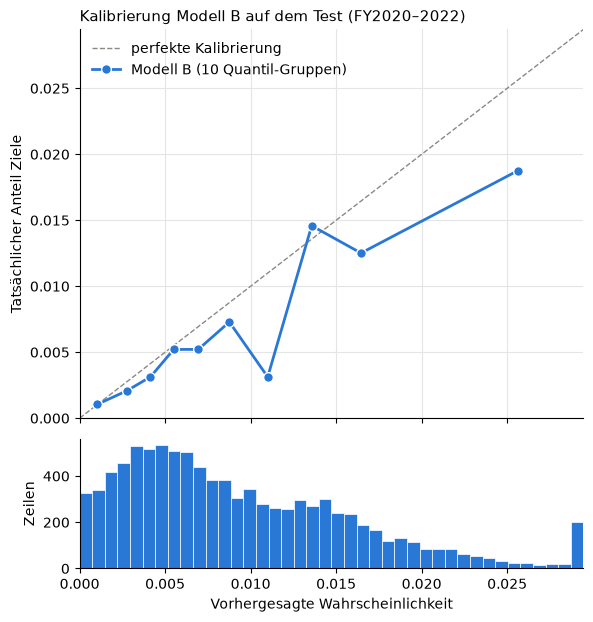

Vorhersagen oberhalb 0.029 (im letzten Balken gesammelt): 191
Mittlere Vorhersage B: 0.958% | A: 0.998% | tatsächliche Basisrate: 0.729%


,Vorhersage_Mittel,Anteil_Ziele,Zeilen,Ziele
bin,,,,
0,0.0010,0.0010,960,1
1,0.0028,0.0021,960,2
2,0.0041,0.0031,959,3
3,0.0055,0.0052,960,5
4,0.0069,0.0052,959,5
5,0.0088,0.0073,960,7
6,0.0110,0.0031,959,3
7,0.0136,0.0146,960,14
8,0.0165,0.0125,959,12


In [14]:
import matplotlib.pyplot as plt

te["bin"] = pd.qcut(te["p_b"], 10, labels=False, duplicates="drop")
calib = te.groupby("bin").agg(Vorhersage_Mittel=("p_b", "mean"), Anteil_Ziele=(Y, "mean"), Zeilen=(Y, "size"), Ziele=(Y, "sum"))

BLUE, GRAY = "#2a78d6", "#8a8984"
limit = max(calib["Vorhersage_Mittel"].max(), calib["Anteil_Ziele"].max()) * 1.15
fig, (ax, axh) = plt.subplots(2, 1, figsize=(6.5, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08})
ax.plot([0, limit], [0, limit], color=GRAY, linestyle="--", linewidth=1, label="perfekte Kalibrierung")
ax.plot(calib["Vorhersage_Mittel"], calib["Anteil_Ziele"], color=BLUE, linewidth=2, marker="o", markersize=7,
        markeredgecolor="white", label="Modell B (10 Quantil-Gruppen)")
ax.set_xlim(0, limit); ax.set_ylim(0, limit)
ax.set_ylabel("Tatsächlicher Anteil Ziele")
ax.set_title("Kalibrierung Modell B auf dem Test (FY2020–2022)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
ax.grid(color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
axh.hist(np.clip(te["p_b"], 0, limit * 0.999), bins=40, range=(0, limit), color=BLUE, edgecolor="white", linewidth=0.5)
axh.set_xlabel("Vorhergesagte Wahrscheinlichkeit"); axh.set_ylabel("Zeilen")
axh.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"Vorhersagen oberhalb {limit:.3f} (im letzten Balken gesammelt): {(te['p_b'] > limit).sum()}")
print(f"Mittlere Vorhersage B: {te['p_b'].mean():.3%} | A: {te['p_a'].mean():.3%} | tatsächliche Basisrate: {y.mean():.3%}")
calib.round(4)

**Ergebnis:** Modell B ist ähnlich gut kalibriert wie A: Die Punkte liegen nahe der Diagonale, mit leichter Überschätzung (Mittel 0,96 % vorhergesagt, 0,73 % tatsächlich). B verteilt die Vorhersagen breiter (von 0,1 % bis über 2,5 %) als A (0,4 % bis 2 %). Das passt dazu, dass B besser zwischen Zielen und Nicht-Zielen unterscheidet.

## 8. Variante B2: Größe quadratisch (nur Training)

Die SHAP-Analyse der Baum-Modelle (Notebook 07) zeigte einen **umgekehrt U-förmigen** Größeneffekt: sehr kleine und große Firmen seltener Ziel, mittelgroße (rund 200–750 Mio. USD Bilanzsumme) am ehesten. Ein Logit mit nur `log_assets` kann das nicht abbilden – es kann nur „je größer, desto mehr“ oder „desto weniger“. Mit einem zusätzlichen **quadratischen Term** kann die Kurve sich biegen.

- `log_assets` wird vorher am **Trainingsmittelwert zentriert**. Sonst wären `log_assets` und `log_assets²` fast perfekt korreliert (beide steigen gemeinsam), und die Koeffizienten wären instabil. Die Zentrierung ändert die Vorhersagen nicht, nur die Konstante.
- Gleiches Setup wie Modell B, **nur Training, keine Test-Auswertung**. Modell B bleibt unverändert.
- Liegt ein umgekehrtes U vor (negativer Koeffizient beim Quadrat), liegt der Scheitelpunkt bei `log_assets` = Mittelwert − b₁ / (2 · b₂).

In [15]:
size_mean = tr["log_assets"].mean()                        # nur Trainingsmittelwert
for d in (tr, te):
    d["log_assets_c"] = d["log_assets"] - size_mean           # zentriert
    d["log_assets_c2"] = d["log_assets_c"] ** 2               # quadratischer Term

B2_COLS = [("log_assets_c" if c == "log_assets" else c) for c in B_COLS]
B2_COLS.insert(B2_COLS.index("log_assets_c") + 1, "log_assets_c2")

print(f"Trainingsmittelwert log_assets: {size_mean:.3f} (= {np.exp(size_mean) / 1e6:,.0f} Mio. USD)")
print(f"Korrelation Größe/Größe² ohne Zentrierung: {np.corrcoef(tr['log_assets'], tr['log_assets'] ** 2)[0, 1]:.3f} | "
      f"mit Zentrierung: {np.corrcoef(tr['log_assets_c'], tr['log_assets_c2'])[0, 1]:.3f}")

res_b2 = fit_logit(B2_COLS)
print("Konvergiert:", res_b2.mle_retvals["converged"])

size_terms = ["log_assets_c", "log_assets_c2"]
display(pd.DataFrame({"Koeffizient": res_b2.params[size_terms], "Std.-Fehler (Cluster)": res_b2.bse[size_terms],
                      "Odds Ratio": np.exp(res_b2.params[size_terms]), "p-Wert": res_b2.pvalues[size_terms]}).round(4))
print(f"Zum Vergleich Modell B: log_assets Koeffizient {res_b.params['log_assets']:.4f}, p = {res_b.pvalues['log_assets']:.3f}")

lr_b2 = 2 * (res_b2.llf - res_b.llf)
print(f"\nLR-Test B2 vs. B: Chi² = {lr_b2:.2f}, df = 1, p = {stats.chi2.sf(lr_b2, 1):.4f}")
print(f"McFadden-R²: B {res_b.prsquared:.2%} | B2 {res_b2.prsquared:.2%}")

Trainingsmittelwert log_assets: 20.403 (= 726 Mio. USD)
Korrelation Größe/Größe² ohne Zentrierung: 0.991 | mit Zentrierung: -0.591
Konvergiert: True


,Koeffizient,Std.-Fehler (Cluster),Odds Ratio,p-Wert
log_assets_c,0.0238,0.0887,1.0241,0.7883
log_assets_c2,-0.0807,0.0315,0.9225,0.0104


Zum Vergleich Modell B: log_assets Koeffizient -0.0278, p = 0.668

LR-Test B2 vs. B: Chi² = 16.58, df = 1, p = 0.0000
McFadden-R²: B 4.55% | B2 5.43%


In [16]:
# Scheitelpunkt (nur sinnvoll, wenn der quadratische Koeffizient negativ ist = umgekehrtes U)
b1, b2 = res_b2.params["log_assets_c"], res_b2.params["log_assets_c2"]
if b2 < 0:
    vertex_c = -b1 / (2 * b2)
    # 95 %-Intervall per Delta-Methode mit der geclusterten Kovarianzmatrix
    V = res_b2.cov_params().loc[size_terms, size_terms].to_numpy()
    grad = np.array([-1 / (2 * b2), b1 / (2 * b2 ** 2)])     # Ableitungen von -b1/(2 b2) nach b1 und b2
    se = np.sqrt(grad @ V @ grad)
    to_musd = lambda c: np.exp(size_mean + c) / 1e6
    print(f"Umgekehrtes U: Scheitelpunkt bei {to_musd(vertex_c):,.0f} Mio. USD Bilanzsumme")
    print(f"  95 %-Intervall (Delta-Methode): {to_musd(vertex_c - 1.96 * se):,.0f} bis {to_musd(vertex_c + 1.96 * se):,.0f} Mio. USD")
    share_below = (tr["log_assets_c"] < vertex_c).mean()
    print(f"  {share_below:.0%} der Trainingszeilen liegen unterhalb des Scheitelpunkts")
else:
    vertex_c = None
    print("Kein umgekehrtes U: der quadratische Koeffizient ist nicht negativ.")

Umgekehrtes U: Scheitelpunkt bei 841 Mio. USD Bilanzsumme
  95 %-Intervall (Delta-Methode): 283 bis 2,502 Mio. USD
  47% der Trainingszeilen liegen unterhalb des Scheitelpunkts


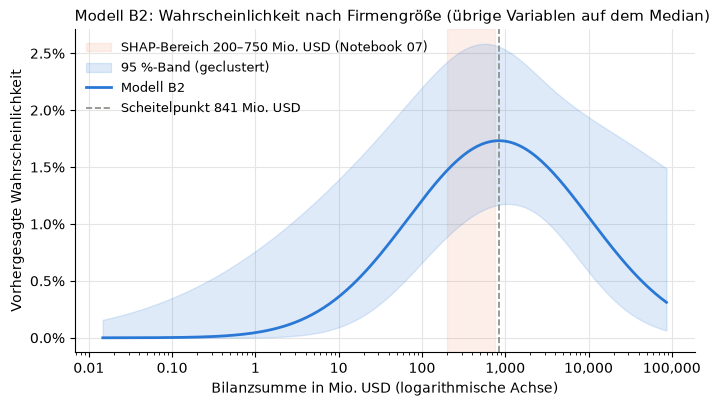

In [17]:
# Vorhergesagte Wahrscheinlichkeit über der Bilanzsumme, alle übrigen Variablen auf dem Trainingsmedian
grid_c = np.linspace(tr["log_assets_c"].quantile(0.01), tr["log_assets_c"].quantile(0.99), 200)
base = tr[B2_COLS].median()
Xg = pd.DataFrame([base] * len(grid_c))
Xg["log_assets_c"], Xg["log_assets_c2"] = grid_c, grid_c ** 2
Xg = sm.add_constant(Xg[B2_COLS], has_constant="add")

eta = Xg.to_numpy() @ res_b2.params.to_numpy()                       # linearer Prädiktor
se_eta = np.sqrt(np.einsum("ij,jk,ik->i", Xg.to_numpy(), res_b2.cov_params().to_numpy(), Xg.to_numpy()))
inv = lambda z: 1 / (1 + np.exp(-z))
assets_musd = np.exp(size_mean + grid_c) / 1e6

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvspan(200, 750, color="#eb6834", alpha=0.10, label="SHAP-Bereich 200–750 Mio. USD (Notebook 07)")
ax.fill_between(assets_musd, inv(eta - 1.96 * se_eta), inv(eta + 1.96 * se_eta), color=BLUE, alpha=0.15,
                label="95 %-Band (geclustert)")
ax.plot(assets_musd, inv(eta), color=BLUE, linewidth=2, label="Modell B2")
if vertex_c is not None:
    ax.axvline(np.exp(size_mean + vertex_c) / 1e6, color=GRAY, linestyle="--", linewidth=1.2,
               label=f"Scheitelpunkt {np.exp(size_mean + vertex_c) / 1e6:,.0f} Mio. USD")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:.2f}"))
ax.set_xlabel("Bilanzsumme in Mio. USD (logarithmische Achse)")
ax.set_ylabel("Vorhergesagte Wahrscheinlichkeit")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Modell B2: Wahrscheinlichkeit nach Firmengröße (übrige Variablen auf dem Median)", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(color="#e5e5e5", linewidth=0.8); ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Ergebnis:**

- **Zentrierung:** Sie senkt die Korrelation zwischen Größe und Größe² von 0,99 auf −0,59.
- **Quadratischer Term:** Er ist **signifikant negativ** (Koeffizient −0,081, OR 0,92, p = 0,010) – es liegt also ein umgekehrtes U vor. Der lineare Term ist am Mittelwert nahe null (p = 0,79).
- **Modellvergleich:** Der LR-Test B2 gegen B ist klar signifikant (Chi² = 16,6, df = 1, p < 0,001), und das McFadden-R² steigt von 4,55 % auf 5,43 %.
- **Scheitelpunkt:** Er liegt bei **rund 840 Mio. USD Bilanzsumme** (95 %-Intervall 283 bis 2.500 Mio. USD). Das passt gut zum SHAP-Bereich von 200–750 Mio. USD aus Notebook 07: Der Bereich liegt komplett im Intervall, der Punktschätzer knapp darüber. Fast die Hälfte der Trainingszeilen (47 %) liegt unterhalb des Scheitelpunkts.
- **Grafik:** Bei sonst typischen Werten steigt die Wahrscheinlichkeit von nahe 0 bei Kleinstfirmen auf etwa 1,7 % am Scheitelpunkt und fällt bei den größten Firmen wieder auf rund 0,3 %. Das Band ist breit, weil es nur 167 Ziele gibt.

## Kernergebnisse

1. **Ist B besser als A?** Im Training ja, klar (McFadden-R² 4,6 % statt 2,0 %, signifikanter LR- und Wald-Test). Im Test steigt die ROC-AUC von 0,63 auf 0,70, aber der Abstand ist statistisch nur knapp an der Grenze (95 %-Intervall −0,0003 bis +0,12).
2. Am Palepu-Cutoff findet B dieselben Ziele wie A mit weniger Fehlalarmen (Lift 1,78 statt 1,46).
3. **Welche neuen Variablen tragen?** Freier Cashflow (positiv), Zinsdeckung und Altman-Z (beide negativ) sind signifikant; das Fehlen von Zinsaufwand senkt die Chance deutlich; Sachanlagen sind nur schwach und negativ.
4. **Was heißt das für die Verschuldung?** Die Höhe der bestehenden Verschuldung erklärt weder in A noch in B etwas. Die Finanzierbarkeit zeigt sich eher im Cashflow: PE-Ziele erwirtschaften freien Cashflow, haben aber schon Schulden mit spürbarer Zinslast und liegen eher näher am Distress-Bereich.
5. Sicherheiten in Form von Sachanlagen spielen dabei keine positive Rolle, und `grdummy` bleibt das stabilste Palepu-Ergebnis (in A und B signifikant negativ).